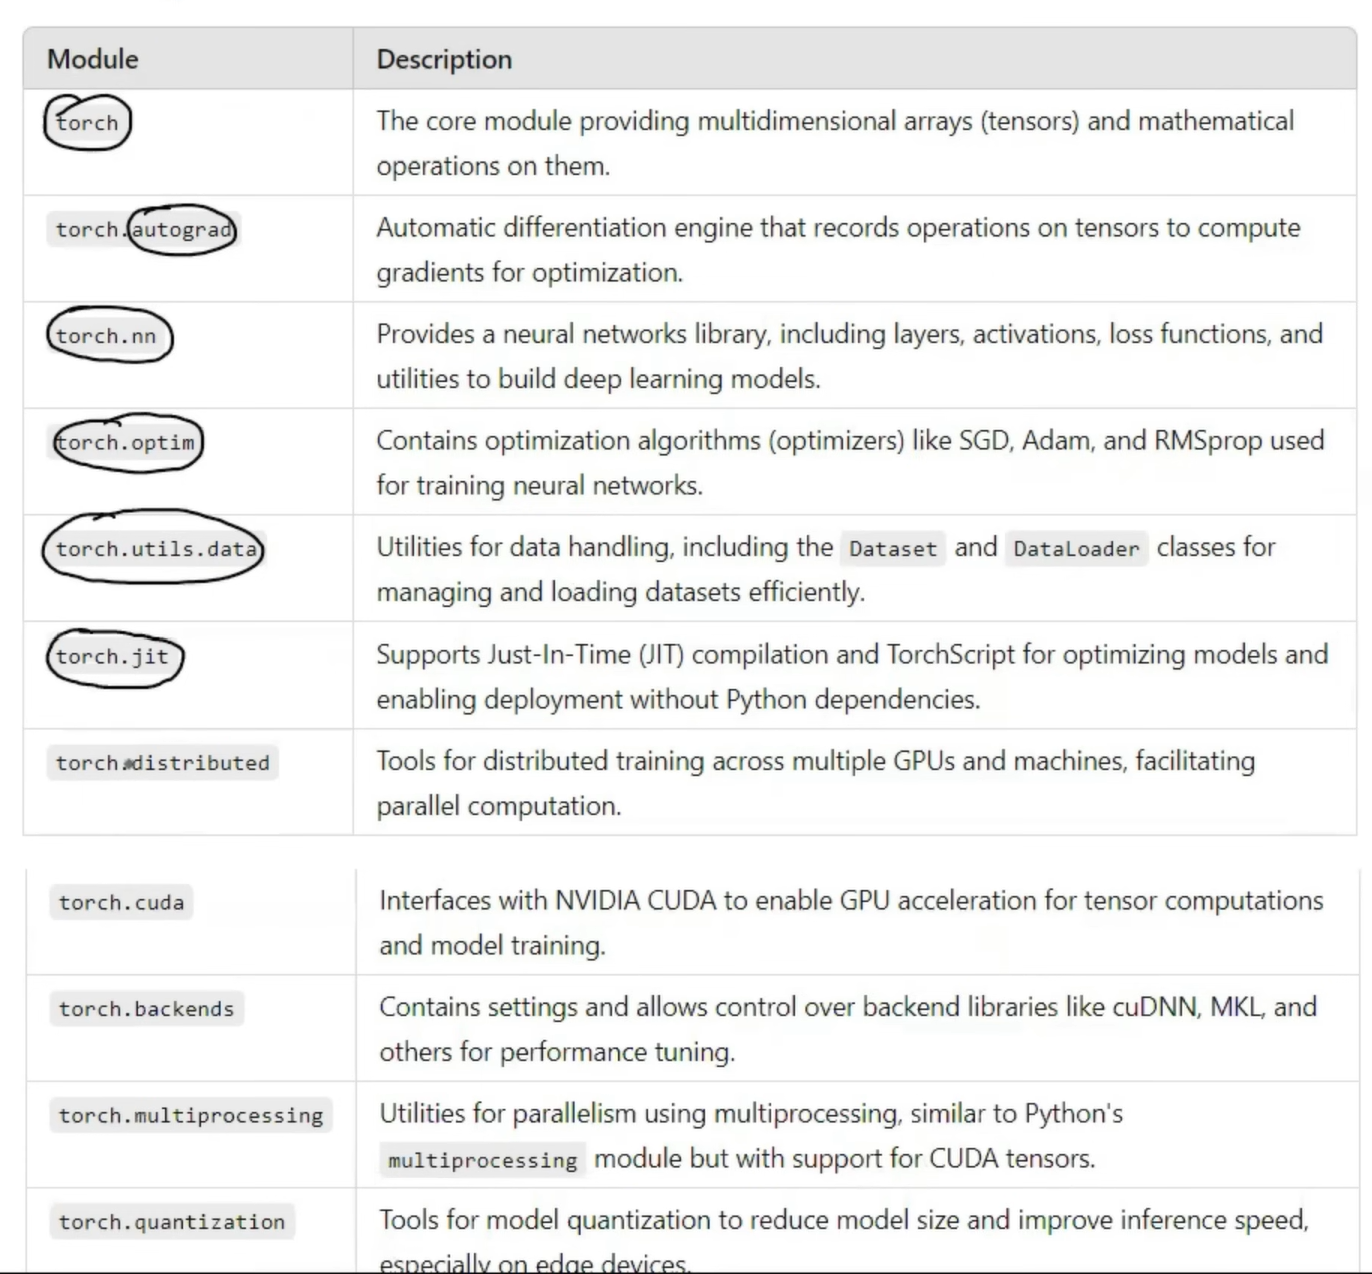

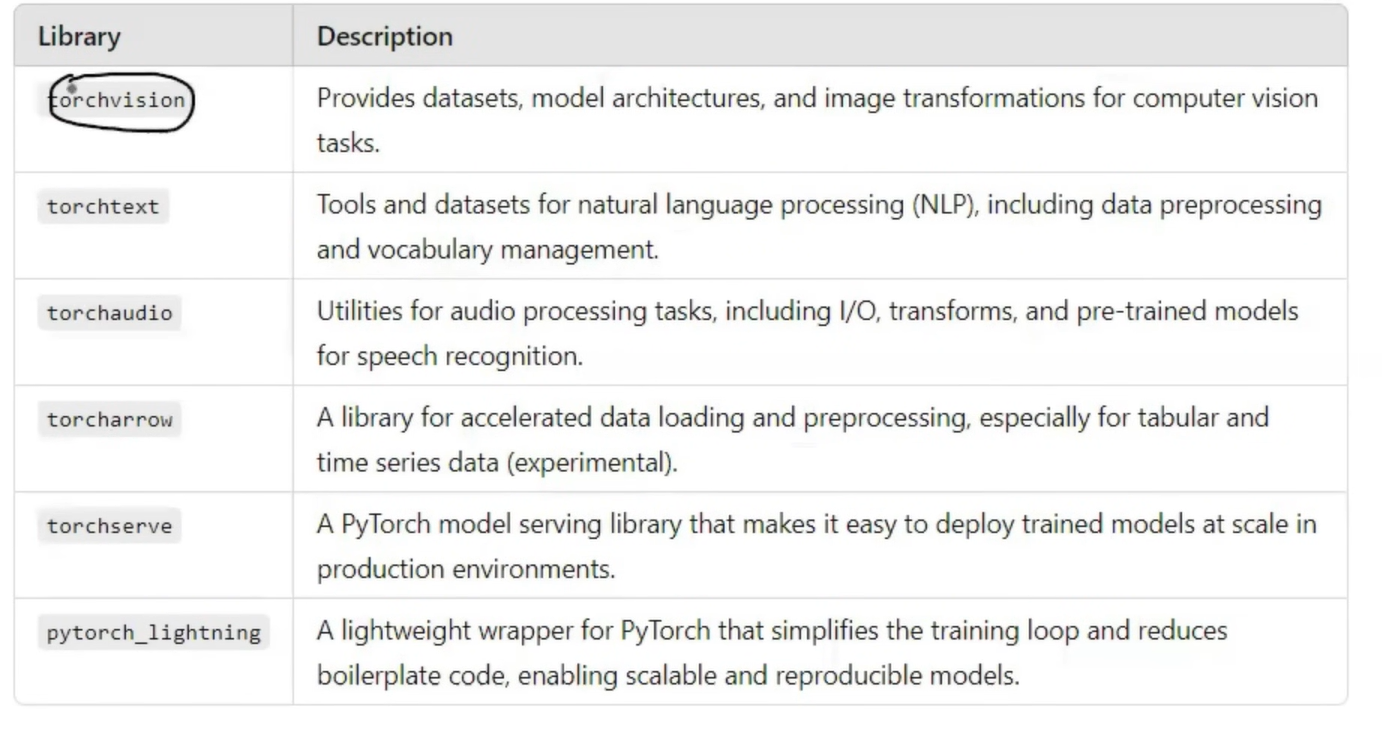

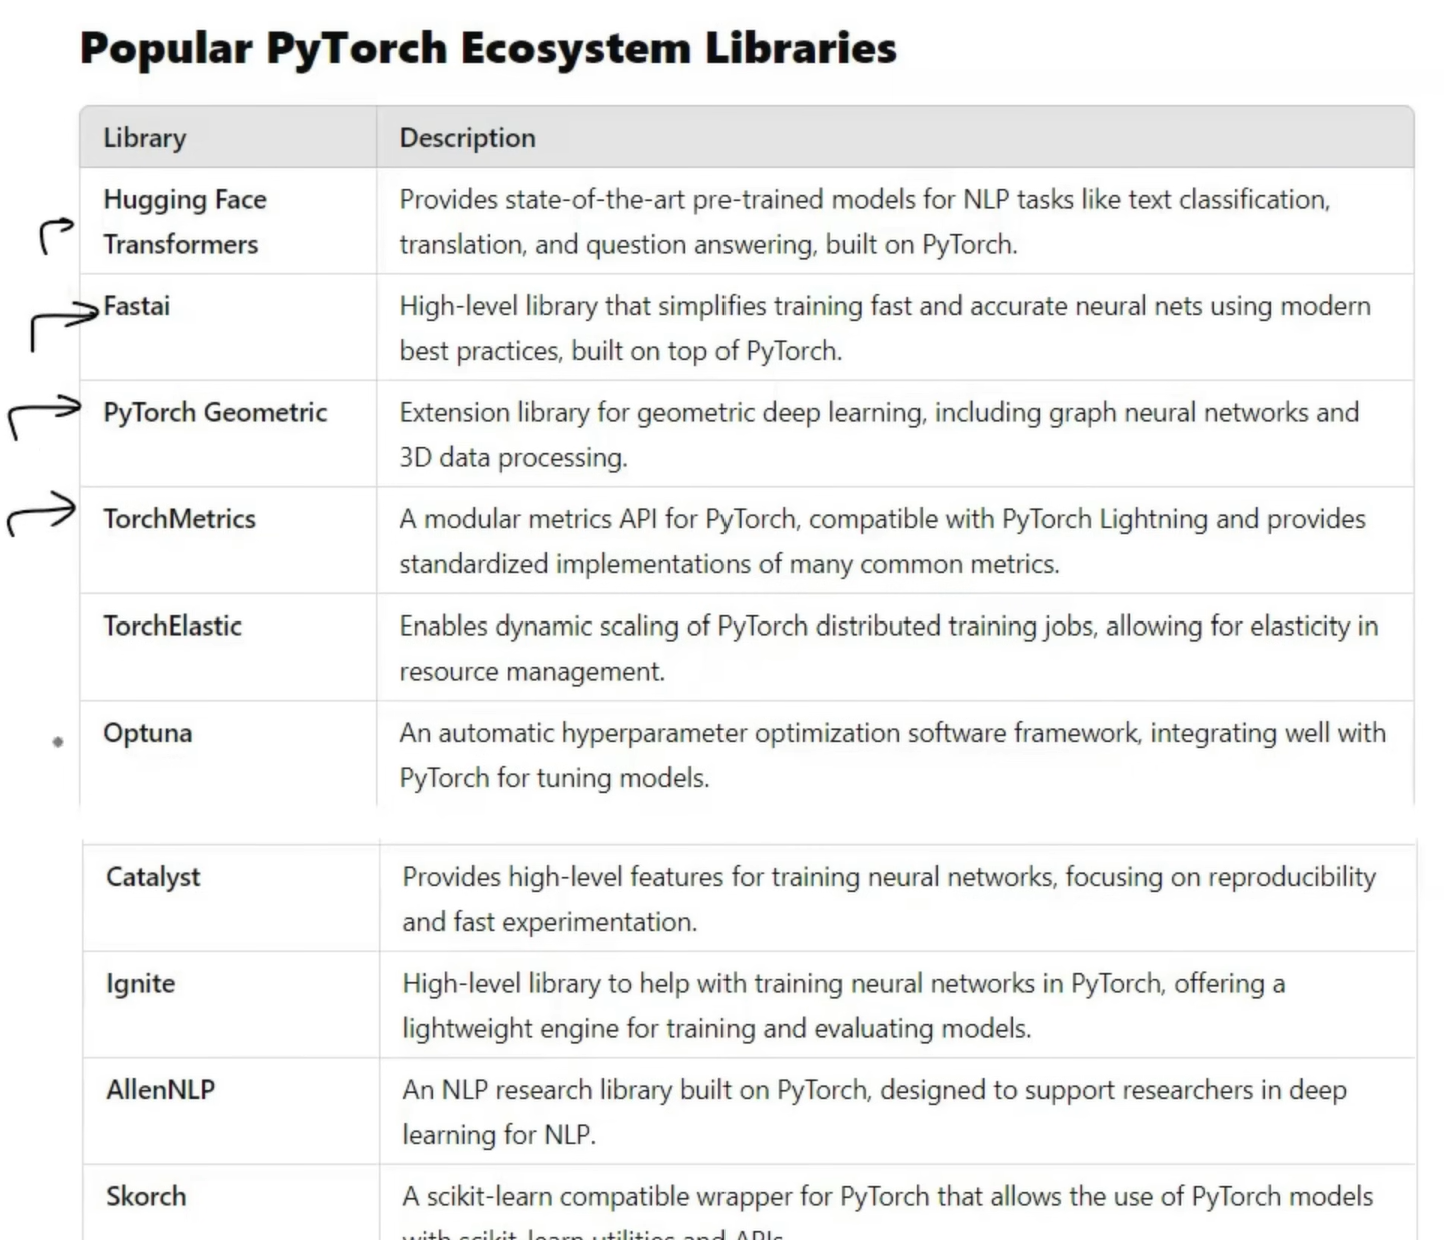

In [2]:
import torch
print(torch.__version__)

2.11.0+cu130


In [3]:
if torch.cuda.is_available(): #tells GPU is avilable or not
  print("GPU is available")
  print(f"Using GPU: {torch.cuda.get_device_name(0)}") #tells which GPU is avilable
else:
  print("GPU not available!")

GPU is available
Using GPU: Tesla T4


## Creating a Tensor

In [4]:
'''what happens behind the scenes when you call torch.empty(2, 3):
1. PyTorch asks your Operating System (OS): "Hey, I need a block of memory big enough to hold 6 floating-point numbers."
2. The OS looks at your RAM: It finds a random, unused slot of memory that a completely different application (like your web browser, a background process, or an old program you just closed) was using earlier.
3. The OS hands it over: The OS hands that exact block of memory to PyTorch.
4. PyTorch just leaves it as-is: To save time, PyTorch does not clear what was written there. It simply overlays a 2x3 grid structure on top of whatever raw binary bits (1s and 0s) were already left behind in that memory slot.'''
a=torch.empty(2,3)

In [5]:
# check type
type(a)

torch.Tensor

In [6]:
# using zeros
torch.zeros(2,3)

tensor([[0., 0., 0.],
        [0., 0., 0.]])

In [7]:
# using ones
torch.ones(2,3)

tensor([[1., 1., 1.],
        [1., 1., 1.]])

In [8]:
# using rand
torch.rand(2,3)

tensor([[0.2523, 0.8528, 0.9879],
        [0.0191, 0.4352, 0.6742]])

In [9]:
# use of seed
torch.rand(2,3)

tensor([[0.8011, 0.5226, 0.7980],
        [0.4310, 0.5561, 0.0167]])

In [10]:
# manual_seed
torch.manual_seed(100)
torch.rand(2,3)

tensor([[0.1117, 0.8158, 0.2626],
        [0.4839, 0.6765, 0.7539]])

In [11]:
torch.manual_seed(100)
torch.rand(2,3)

tensor([[0.1117, 0.8158, 0.2626],
        [0.4839, 0.6765, 0.7539]])

In [12]:
# using tensor
torch.tensor([[1,2,3],[4,5,6]])

tensor([[1, 2, 3],
        [4, 5, 6]])

In [13]:
# other ways

# arange
print("using arange ->", torch.arange(0,10,2))

# using linspace
print("using linspace ->", torch.linspace(0,10,10))

# using eye
print("using eye ->", torch.eye(5))

# using full
print("using full ->", torch.full((3, 3), 5))

using arange -> tensor([0, 2, 4, 6, 8])
using linspace -> tensor([ 0.0000,  1.1111,  2.2222,  3.3333,  4.4444,  5.5556,  6.6667,  7.7778,
         8.8889, 10.0000])
using eye -> tensor([[1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 1.]])
using full -> tensor([[5, 5, 5],
        [5, 5, 5],
        [5, 5, 5]])


## Tensor Shapes

In [14]:
x = torch.tensor([[1,2,3],[4,5,6]])
x

tensor([[1, 2, 3],
        [4, 5, 6]])

In [15]:
x.shape

torch.Size([2, 3])

In [16]:
torch.empty_like(x)

tensor([[0, 0, 0],
        [0, 1, 0]])

In [17]:
torch.zeros_like(x)

tensor([[0, 0, 0],
        [0, 0, 0]])

In [18]:
torch.ones_like(x)

tensor([[1, 1, 1],
        [1, 1, 1]])

In [19]:
torch.rand_like(x, dtype=torch.float32)

tensor([[0.2627, 0.0428, 0.2080],
        [0.1180, 0.1217, 0.7356]])

## Tensor Data Types

In [20]:
# find data type
x.dtype

torch.int64

In [21]:
# assign data type
torch.tensor([1.0,2.0,3.0], dtype=torch.int32)

tensor([1, 2, 3], dtype=torch.int32)

In [22]:
torch.tensor([1,2,3], dtype=torch.float64)

tensor([1., 2., 3.], dtype=torch.float64)

In [23]:
# using to()
x.to(torch.float32)

tensor([[1., 2., 3.],
        [4., 5., 6.]])

| **Data Type**             | **Dtype**         | **Description**                                                                                                                                                                |
|---------------------------|-------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **32-bit Floating Point** | `torch.float32`   | Standard floating-point type used for most deep learning tasks. Provides a balance between precision and memory usage.                                                         |
| **64-bit Floating Point** | `torch.float64`   | Double-precision floating point. Useful for high-precision numerical tasks but uses more memory.                                                                               |
| **16-bit Floating Point** | `torch.float16`   | Half-precision floating point. Commonly used in mixed-precision training to reduce memory and computational overhead on modern GPUs.                                            |
| **BFloat16**              | `torch.bfloat16`  | Brain floating-point format with reduced precision compared to `float16`. Used in mixed-precision training, especially on TPUs.                                                |
| **8-bit Floating Point**  | `torch.float8`    | Ultra-low-precision floating point. Used for experimental applications and extreme memory-constrained environments (less common).                                               |
| **8-bit Integer**         | `torch.int8`      | 8-bit signed integer. Used for quantized models to save memory and computation in inference.                                                                                   |
| **16-bit Integer**        | `torch.int16`     | 16-bit signed integer. Useful for special numerical tasks requiring intermediate precision.                                                                                    |
| **32-bit Integer**        | `torch.int32`     | Standard signed integer type. Commonly used for indexing and general-purpose numerical tasks.                                                                                  |
| **64-bit Integer**        | `torch.int64`     | Long integer type. Often used for large indexing arrays or for tasks involving large numbers.                                                                                  |
| **8-bit Unsigned Integer**| `torch.uint8`     | 8-bit unsigned integer. Commonly used for image data (e.g., pixel values between 0 and 255).                                                                                    |
| **Boolean**               | `torch.bool`      | Boolean type, stores `True` or `False` values. Often used for masks in logical operations.                                                                                      |
| **Complex 64**            | `torch.complex64` | Complex number type with 32-bit real and 32-bit imaginary parts. Used for scientific and signal processing tasks.                                                               |
| **Complex 128**           | `torch.complex128`| Complex number type with 64-bit real and 64-bit imaginary parts. Offers higher precision but uses more memory.                                                                 |
| **Quantized Integer**     | `torch.qint8`     | Quantized signed 8-bit integer. Used in quantized models for efficient inference.                                                                                              |
| **Quantized Unsigned Integer** | `torch.quint8` | Quantized unsigned 8-bit integer. Often used for quantized tensors in image-related tasks.                                                                                     |


## Mathematical operations

### 1. Scalar operation

In [24]:
x = torch.rand(2,2)
x

tensor([[0.7118, 0.7876],
        [0.4183, 0.9014]])

In [25]:
# addition
x + 2
# substraction
x - 2
# multiplication
x * 3
# division
x / 3
# int division
(x * 100)//3
# mod
((x * 100)//3)%2
# power
x**2

tensor([[0.5066, 0.6203],
        [0.1750, 0.8125]])

### 2. Element wise operation

In [26]:
a = torch.rand(2,3)
b = torch.rand(2,3)

print(a)
print(b)

tensor([[0.9969, 0.7565, 0.2239],
        [0.3023, 0.1784, 0.8238]])
tensor([[0.5557, 0.9770, 0.4440],
        [0.9478, 0.7445, 0.4892]])


In [27]:
# add
a + b
# sub
a - b
# multiply
a * b
# division
a / b
# power
a ** b
# mod
a % b

tensor([[0.4411, 0.7565, 0.2239],
        [0.3023, 0.1784, 0.3346]])

In [28]:
c = torch.tensor([1, -2, 3, -4])

In [29]:
# abs
torch.abs(c)

tensor([1, 2, 3, 4])

In [30]:
# negative
torch.neg(c)

tensor([-1,  2, -3,  4])

In [31]:
d = torch.tensor([1.9, 2.3, 3.7, 4.4])

In [32]:
# round
torch.round(d)

tensor([2., 2., 4., 4.])

In [33]:
# ceil
torch.ceil(d)

tensor([2., 3., 4., 5.])

In [34]:
# floor
torch.floor(d)

tensor([1., 2., 3., 4.])

In [35]:
# clamp
torch.clamp(d, min=2, max=3)

tensor([2.0000, 2.3000, 3.0000, 3.0000])

### 3. Reduction operation

In [36]:
e = torch.randint(size=(2,3), low=0, high=10, dtype=torch.float32)
e

tensor([[8., 0., 7.],
        [0., 0., 9.]])

In [37]:
# sum
torch.sum(e)
# sum along columns
torch.sum(e, dim=0)
# sum along rows
torch.sum(e, dim=1)

tensor([15.,  9.])

In [38]:
# mean
torch.mean(e)
# mean along col
torch.mean(e, dim=0)

tensor([4., 0., 8.])

In [39]:
# median
torch.median(e)

tensor(0.)

In [40]:
# max and min
torch.max(e)
torch.min(e)

tensor(0.)

In [41]:
# product
torch.prod(e)

tensor(0.)

In [42]:
# standard deviation
torch.std(e)

tensor(4.4272)

In [43]:
# variance
torch.var(e)

tensor(19.6000)

In [44]:
# argmax
torch.argmax(e)

tensor(5)

In [45]:
# argmin
torch.argmin(e)

tensor(1)

### 4. Matrix operations

In [46]:
f = torch.randint(size=(2,3), low=0, high=10)
g = torch.randint(size=(3,2), low=0, high=10)

print(f)
print(g)

tensor([[5, 7, 3],
        [9, 4, 0]])
tensor([[5, 7],
        [5, 9],
        [9, 7]])


In [47]:
# matrix multiplcation
torch.matmul(f, g)

tensor([[ 87, 119],
        [ 65,  99]])

In [48]:
vector1 = torch.tensor([1, 2])
vector2 = torch.tensor([3, 4])

# dot product
torch.dot(vector1, vector2)

tensor(11)

In [49]:
# transpose
torch.transpose(f, 0, 1)

tensor([[5, 9],
        [7, 4],
        [3, 0]])

In [50]:
h = torch.randint(size=(3,3), low=0, high=10, dtype=torch.float32)
h

tensor([[5., 9., 8.],
        [9., 7., 9.],
        [2., 6., 7.]])

In [51]:
# determinant
torch.det(h)

tensor(-110.)

In [52]:
# inverse
torch.inverse(h)

tensor([[ 0.0455,  0.1364, -0.2273],
        [ 0.4091, -0.1727, -0.2455],
        [-0.3636,  0.1091,  0.4182]])

### 5. Comparison operations

In [53]:
i = torch.randint(size=(2,3), low=0, high=10)
j = torch.randint(size=(2,3), low=0, high=10)

print(i)
print(j)

tensor([[7, 8, 3],
        [6, 1, 5]])
tensor([[5, 0, 4],
        [3, 8, 8]])


In [54]:
# greater than
i > j
# less than
i < j
# equal to
i == j
# not equal to
i != j
# greater than equal to

# less than equal to

tensor([[True, True, True],
        [True, True, True]])

### 6. Special functions

In [55]:
k = torch.randint(size=(2,3), low=0, high=10, dtype=torch.float32)
k

tensor([[3., 3., 5.],
        [0., 6., 4.]])

In [56]:
# log
torch.log(k)

tensor([[1.0986, 1.0986, 1.6094],
        [  -inf, 1.7918, 1.3863]])

In [57]:
# exp
torch.exp(k)

tensor([[ 20.0855,  20.0855, 148.4132],
        [  1.0000, 403.4288,  54.5981]])

In [58]:
# sqrt
torch.sqrt(k)

tensor([[1.7321, 1.7321, 2.2361],
        [0.0000, 2.4495, 2.0000]])

In [59]:
# sigmoid
torch.sigmoid(k)

tensor([[0.9526, 0.9526, 0.9933],
        [0.5000, 0.9975, 0.9820]])

In [60]:
# softmax
torch.softmax(k, dim=0)

tensor([[0.9526, 0.0474, 0.7311],
        [0.0474, 0.9526, 0.2689]])

In [61]:
# relu
torch.relu(k)

tensor([[3., 3., 5.],
        [0., 6., 4.]])

## Inplace Operations

In [62]:
m = torch.rand(2,3)
n = torch.rand(2,3)

print(m)
print(n)

tensor([[0.6574, 0.3451, 0.0453],
        [0.9798, 0.5548, 0.6868]])
tensor([[0.4920, 0.0748, 0.9605],
        [0.3271, 0.0103, 0.9516]])


In [63]:
m.add_(n) #this _ after name of operation defines the inplace operation

tensor([[1.1494, 0.4199, 1.0058],
        [1.3069, 0.5650, 1.6384]])

In [64]:
m

tensor([[1.1494, 0.4199, 1.0058],
        [1.3069, 0.5650, 1.6384]])

In [65]:
n

tensor([[0.4920, 0.0748, 0.9605],
        [0.3271, 0.0103, 0.9516]])

In [66]:
torch.relu(m)

tensor([[1.1494, 0.4199, 1.0058],
        [1.3069, 0.5650, 1.6384]])

In [67]:
m.relu_()

tensor([[1.1494, 0.4199, 1.0058],
        [1.3069, 0.5650, 1.6384]])

In [68]:
m

tensor([[1.1494, 0.4199, 1.0058],
        [1.3069, 0.5650, 1.6384]])

## Copying a Tensor

In [69]:
a = torch.rand(2,3)
a

tensor([[0.2855, 0.2324, 0.9141],
        [0.7668, 0.1659, 0.4393]])

In [70]:
b = a

In [71]:
b

tensor([[0.2855, 0.2324, 0.9141],
        [0.7668, 0.1659, 0.4393]])

In [72]:
a[0][0] = 0

In [73]:
a #when we make the value of a[0][0]=0 then that would also reflact in teh

tensor([[0.0000, 0.2324, 0.9141],
        [0.7668, 0.1659, 0.4393]])

In [74]:
b

tensor([[0.0000, 0.2324, 0.9141],
        [0.7668, 0.1659, 0.4393]])

In [75]:
id(a)

139283121188336

In [76]:
id(b) #id of both a and b are same

139283121188336

In [77]:
b = a.clone() #use clone

In [78]:
a

tensor([[0.0000, 0.2324, 0.9141],
        [0.7668, 0.1659, 0.4393]])

In [79]:
b

tensor([[0.0000, 0.2324, 0.9141],
        [0.7668, 0.1659, 0.4393]])

In [80]:
a[0][0] = 10

In [81]:
a

tensor([[10.0000,  0.2324,  0.9141],
        [ 0.7668,  0.1659,  0.4393]])

In [82]:
b

tensor([[0.0000, 0.2324, 0.9141],
        [0.7668, 0.1659, 0.4393]])

In [83]:
id(a)

139283121188336

In [84]:
id(b)

139283121278000

## operations on GPU

In [85]:
torch.cuda.is_available()

True

In [86]:
device=torch.device('cuda')

In [87]:
#creating a new tensor on GPU
torch.rand((2,3),device=device)

tensor([[0.3563, 0.0303, 0.7088],
        [0.2009, 0.0224, 0.9896]], device='cuda:0')

In [88]:
#on CPU
a=torch.rand(2,3)
a

tensor([[0.2243, 0.8935, 0.0497],
        [0.1780, 0.3011, 0.1893]])

In [89]:
#moving tensor of CPU to GPU
a.to(device)


tensor([[0.2243, 0.8935, 0.0497],
        [0.1780, 0.3011, 0.1893]], device='cuda:0')

In [90]:
a+5  #this is still running on CPU so store the tensor that is in CPU and
#now u have stored it in the GPU on a tensor

tensor([[5.2243, 5.8935, 5.0497],
        [5.1780, 5.3011, 5.1893]])

In [91]:
b=a.to(device)
b

tensor([[0.2243, 0.8935, 0.0497],
        [0.1780, 0.3011, 0.1893]], device='cuda:0')

In [92]:
b+5 #now that is on the GPU

tensor([[5.2243, 5.8935, 5.0497],
        [5.1780, 5.3011, 5.1893]], device='cuda:0')

measuring time on GPU and CPU

In [93]:
import time

# Check if GPU is available, otherwise fallback to CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}\n")

size = 1000
a = torch.rand(size, size)
b = torch.rand(size, size)

# 1. Measure CPU Time
start_CPU = time.time()
result_CPU = torch.matmul(a, b)
end_CPU = time.time()

# 2. Move Tensors to GPU for the GPU test
a_gpu = a.to(device)
b_gpu = b.to(device)

# Warm-up call (GPU initialization can skew the first measurement)
if device == "cuda":
    _ = torch.matmul(a_gpu, b_gpu)
    torch.cuda.synchronize()

# Measure GPU Time
start_GPU = time.time()
result_GPU = torch.matmul(a_gpu, b_gpu)

if device == "cuda":
    torch.cuda.synchronize()  # Wait for GPU operation to finish
end_GPU = time.time() # Added missing parenthesis ()

print(f"Time Taken by CPU: {end_CPU - start_CPU:.6f} seconds")
print(f"Time Taken by GPU: {end_GPU - start_GPU:.6f} seconds")


Using device: cuda

Time Taken by CPU: 0.038543 seconds
Time Taken by GPU: 0.001301 seconds


Reshaping Tensors

In [96]:
a=torch.rand(4,4)
a


tensor([[0.3234, 0.5739, 0.9485, 0.2220],
        [0.2173, 0.3704, 0.1317, 0.1610],
        [0.9557, 0.1248, 0.7583, 0.6898],
        [0.6519, 0.4037, 0.8527, 0.2712]])

In [97]:
a.reshape(2,2,2,2)

tensor([[[[0.3234, 0.5739],
          [0.9485, 0.2220]],

         [[0.2173, 0.3704],
          [0.1317, 0.1610]]],


        [[[0.9557, 0.1248],
          [0.7583, 0.6898]],

         [[0.6519, 0.4037],
          [0.8527, 0.2712]]]])

In [102]:
#permute
b=torch.rand(2,3,4)
b


tensor([[[0.5555, 0.2734, 0.2748, 0.2279],
         [0.5558, 0.3740, 0.7577, 0.6966],
         [0.2440, 0.9491, 0.0462, 0.6707]],

        [[0.6196, 0.3903, 0.1519, 0.9389],
         [0.2381, 0.7506, 0.8595, 0.1887],
         [0.2658, 0.0558, 0.9331, 0.9485]]])

In [107]:
b.permute(2,0,1).shape #its shape would be permuted at that instance that would not be permanent

torch.Size([4, 2, 3])

In [106]:
b.shape

torch.Size([2, 3, 4])

In [99]:
a.flatten()
a

tensor([[0.3234, 0.5739, 0.9485, 0.2220],
        [0.2173, 0.3704, 0.1317, 0.1610],
        [0.9557, 0.1248, 0.7583, 0.6898],
        [0.6519, 0.4037, 0.8527, 0.2712]])

### Testcase 1:
#### while working in batches of image you have to chnage the dimension of the existing tensor

In [132]:
#use unsqueeze - adding dimensions as
#{ tensor_name.unsqueeze(index_at_dimention_to_be_Added)}

c=torch.rand(2,3,4)
c.unsqueeze_(3).shape #adding dimension at 3rd index

torch.Size([2, 3, 4, 1])

In [133]:
c.shape

torch.Size([2, 3, 4, 1])

#### squeeze
torch.squeeze() (and its in-place variant squeeze_()) only removes a dimension if its size is exactly 1.

In [134]:
c.squeeze_(2).shape #does not remove the 2nd dimention

torch.Size([2, 3, 4, 1])

In [135]:
c.squeeze_(3).shape #so just remove the dimention whose size is exactly 1

torch.Size([2, 3, 4])

In [136]:
c.shape

torch.Size([2, 3, 4])

### Numpy and PyTorch

In [137]:
import numpy as np

tensor to numpy convertion

In [138]:
a=torch.tensor([1,2,3])
a

tensor([1, 2, 3])

In [140]:
b=a.numpy() #convert tensor to numpy array
b

array([1, 2, 3])

numpy to tensor convertion

In [142]:
c=np.array([1,2,3,4])
c

array([1, 2, 3, 4])

In [143]:
torch.from_numpy(c)

tensor([1, 2, 3, 4])